# Лабораторная работа № 2. Прогнозирование временных рядов с использованием нейронных сетей

## ( “Нейросетевые технологии обработки данных”)

### студентки 4-го курса 10-ой группы

### Ярмош Алеси

### Вариант 13

y(t) = 0.01t + 2 sin(2πt/10) + 0.5 sin(2πt/33)      N(0, 0.252)

Это синтетический временной ряд из 450 точек, включающий слабый линейный рост, двухкомпонентную сезонность с коротким (10 шагов) и длинным (33 шага) циклами, а также умеренный гауссов шум.

Благодаря наличию двух наложенных синусоид с разными периодами он моделирует сложные природные или экономические процессы, где одновременно действуют несколько циклических факторов.

## Постановка задачи

Смоделировать заданный временной ряд по формуле из своего варианта, сформировать
обучающую выборку методом скользящего окна, обучить МСП предсказывать следующее
значение ряда, построить одношаговый и рекурсивный многошаговый прогнозы, оценить
их качество.

In [65]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

In [66]:
torch.manual_seed(7)
np.random.seed(7)

In [67]:
# 1. Синтетический временной ряд: тренд + сезонность + шум
N = 400
t = np.arange(N)
series = (0.01 * t + 2 * np.sin(2 * np.pi * t / 10) + 0.5 * np.sin(2 * np.pi * t / 33) + np.random.normal(0, 0.25, N)).astype(np.float32)

Слишком узкое окно не «видит» достаточно длинных периодических зависимостей (например, окно короче периода сезонности не позволит сети
выучить сезонность напрямую); слишком широкое окно увеличивает число входов и параметров сети, повышая риск переобучения при ограниченном объёме данных. На практике
W подбирают, ориентируясь на предполагаемый период колебаний ряда (если он известен
из предметной области или виден на графике) и экспериментально сравнивая ошибку
прогноза.

Окно должно покрывать как минимум 1-2 полных цикла для САМОГО длинного периода.

In [ ]:
# Т.к. самый длинный период у меня это 33, то возьмем окна 33, 66, 100, 135
w_sizes = [33, 66, 100, 135]

windows = {}

for w_size in w_sizes:
    w_num = N - w_size
    train_w_num = int(w_num * 0.8)

    X, Y = [], []
    for i in range(N - w_size):
        X.append(series[i:i + w_size])
        Y.append([series[i + w_size]])
    X = np.array(X, dtype=np.float32)
    Y = np.array(Y, dtype=np.float32)

    # В словаре для каждого размера окна храним словарь окон train и test
    windows[w_size] = {
        'X_train': X[:train_w_num],
        'Y_train': Y[:train_w_num],
        'X_test': X[train_w_num:],
        'Y_test': Y[train_w_num:]
    }


## График траектории ряда и разбиения на train/test в зависимости от размера окна

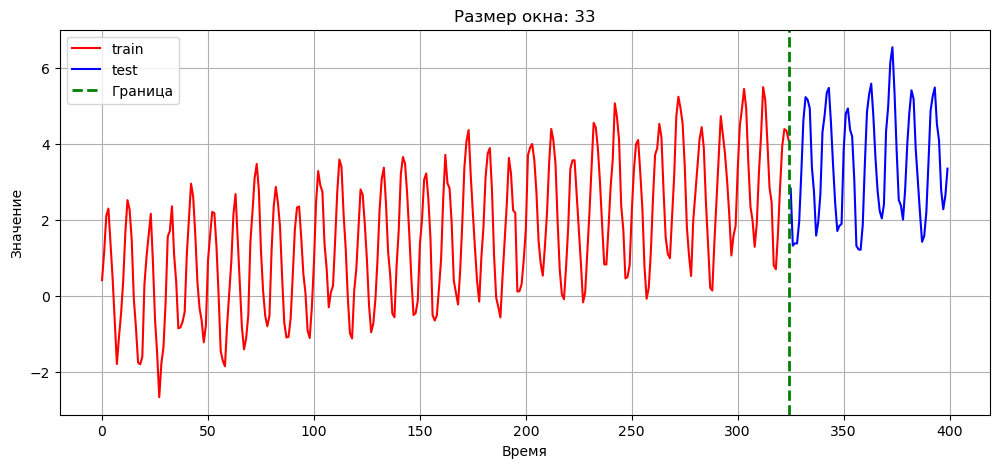

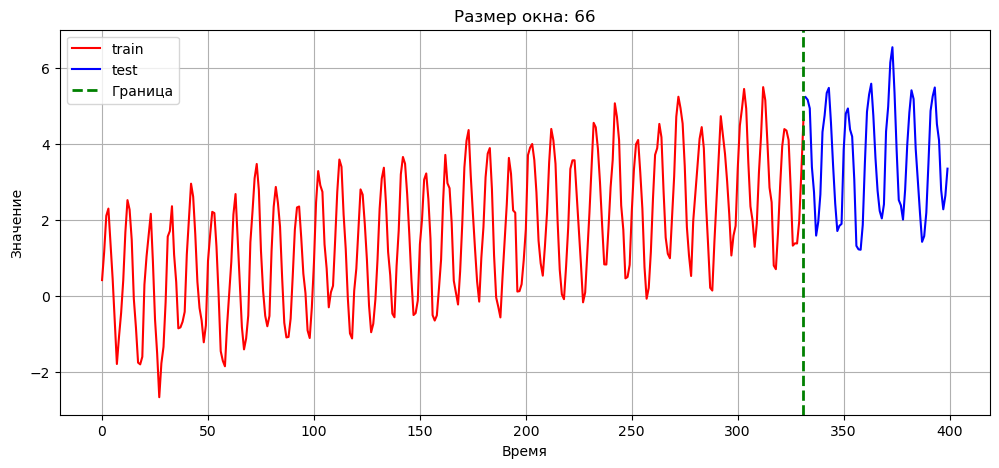

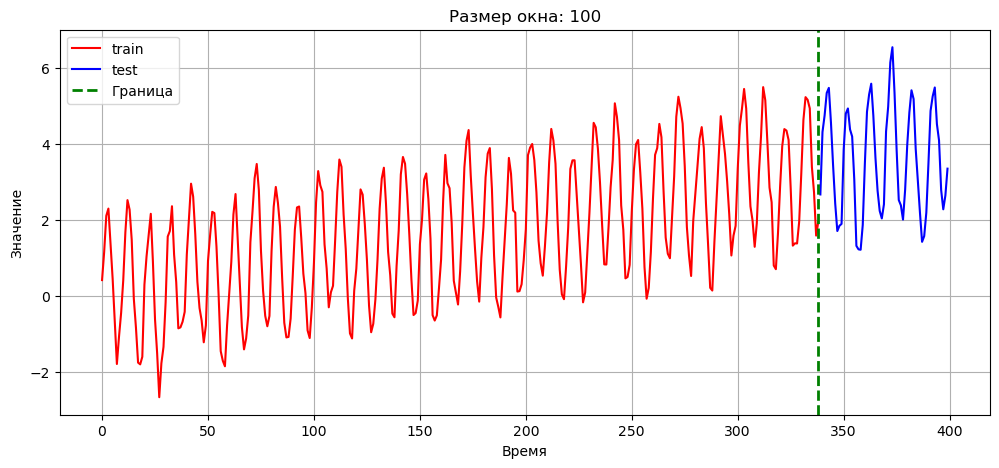

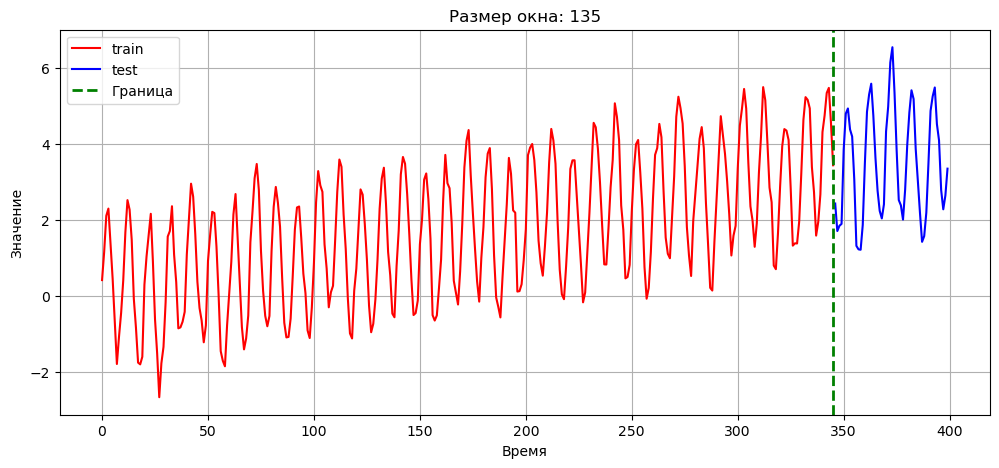

In [69]:
for size, window in windows.items():
    plt.figure(figsize=(12, 5))

    train_end = len(window['Y_train']) + size - 1

    plt.plot(
        np.arange(train_end),
        series[:train_end],
        color='red',
        label='train'
    )

    plt.plot(
        np.arange(train_end, len(series)),
        series[train_end:],
        color='blue',
        label='test'
    )

    plt.axvline(
        x=train_end - 1,
        color='green',
        linestyle='--',
        linewidth=2,
        label='Граница'
    )

    plt.title(f'Размер окна: {size}')
    plt.xlabel('Время')
    plt.ylabel('Значение')
    plt.legend()
    plt.grid()
    plt.show()

In [ ]:
# 4. Архитектура: window (ReLU) -> window (ReLU) -> 1 (линейный)
class MLP(nn.Module):
    def __init__(self, window, hidden=32):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(window, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, 1),
            )
    def forward(self, x):
        return self.net(x)

Размер окна: 33
Число параметров сети: 2177
Финальная MSE на обучении: 0.001753
Одношаговый MAE: 0.3583
Одношаговый RMSE: 0.4530
Рекурсивный MAE: 0.6087
Рекурсивный RMSE: 0.7937
Наивный MAE: 0.7612
Наивный RMSE: 0.9151



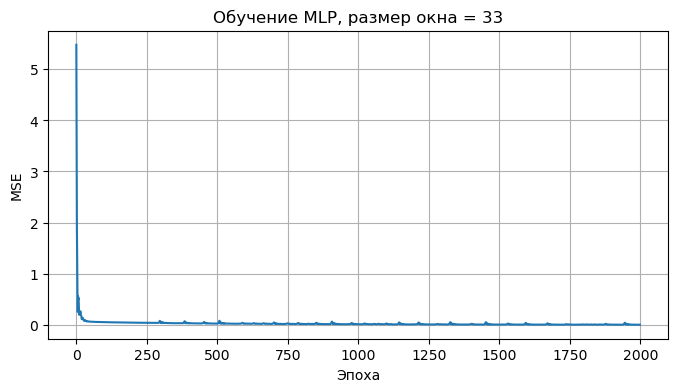

Размер окна: 66
Число параметров сети: 3233
Финальная MSE на обучении: 0.001559
Одношаговый MAE: 0.3189
Одношаговый RMSE: 0.4101
Рекурсивный MAE: 0.3414
Рекурсивный RMSE: 0.4283
Наивный MAE: 0.7599
Наивный RMSE: 0.9096



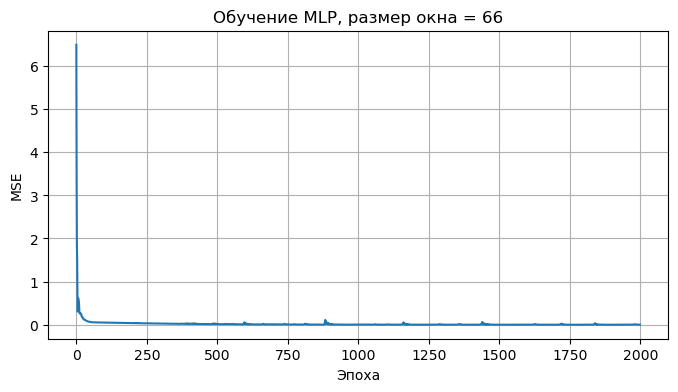

Размер окна: 100
Число параметров сети: 4321
Финальная MSE на обучении: 0.005052
Одношаговый MAE: 0.3115
Одношаговый RMSE: 0.4185
Рекурсивный MAE: 0.3336
Рекурсивный RMSE: 0.4471
Наивный MAE: 0.7698
Наивный RMSE: 0.9183



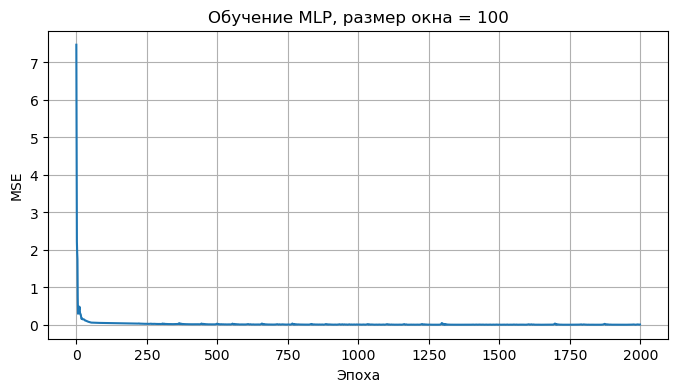

Размер окна: 135
Число параметров сети: 5441
Финальная MSE на обучении: 0.002448
Одношаговый MAE: 0.2780
Одношаговый RMSE: 0.3853
Рекурсивный MAE: 0.3078
Рекурсивный RMSE: 0.4111
Наивный MAE: 0.7612
Наивный RMSE: 0.9136



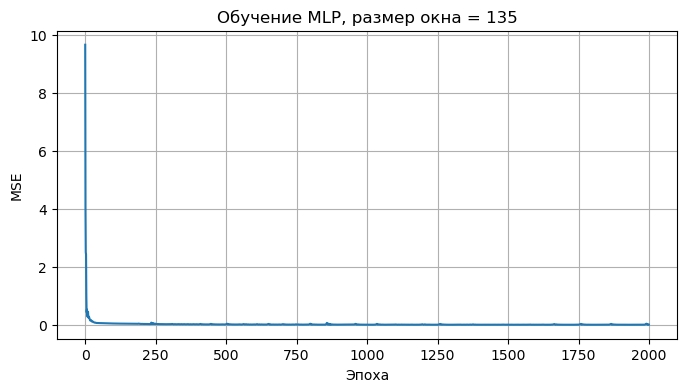

| Размер окна | Одношаговый MAE | Одношаговый RMSE | Рекурсивный MAE | Рекурсивный RMSE | Наивный MAE | Наивный RMSE |
|---:|---:|---:|---:|---:|---:|---:|
| 33 | 0.3583 | 0.4530 | 0.6087 | 0.7937 | 0.7612 | 0.9151 |
| 66 | 0.3189 | 0.4101 | 0.3414 | 0.4283 | 0.7599 | 0.9096 |
| 100 | 0.3115 | 0.4185 | 0.3336 | 0.4471 | 0.7698 | 0.9183 |
| 135 | 0.2780 | 0.3853 | 0.3078 | 0.4111 | 0.7612 | 0.9136 |

In [71]:
recursive_preds = []
one_step_preds = []
one_step_mae_results = {}
mae_results = []
models = {}

for w_size, window in windows.items():

    # Достаём данные из словаря
    X_train = window['X_train']
    Y_train = window['Y_train']
    X_test = window['X_test']
    Y_test = window['Y_test']

    # Создаём модель
    model = MLP(w_size)
    opt = torch.optim.Adam(model.parameters(), lr=0.01)
    loss_fn = nn.MSELoss()

    loss_history = []

    # Переводим данные в tensor
    X_tr = torch.tensor(X_train, dtype=torch.float32)
    Y_tr = torch.tensor(Y_train, dtype=torch.float32)

    X_tst = torch.tensor(X_test, dtype=torch.float32)
    Y_tst = torch.tensor(Y_test, dtype=torch.float32)

    # Обучение
    for epoch in range(2000):
        opt.zero_grad()

        pred = model(X_tr)
        loss = loss_fn(pred, Y_tr)

        loss.backward()
        opt.step()

        loss_history.append(loss.item())
    
    models[w_size] = model

    # =========================================================
    # 1. Одношаговый прогноз
    # =========================================================

    with torch.no_grad():
        pred_test = model(X_tst).numpy().flatten()

    Y_tst_np = Y_tst.numpy().flatten()

    one_step_preds.append(pred_test)

    mae_1step = np.mean(np.abs(pred_test - Y_tst_np))
    one_step_mae_results[w_size] = mae_1step
    rmse_1step = np.sqrt(np.mean((pred_test - Y_tst_np) ** 2))

    # =========================================================
    # 2. Наивный прогноз: y(t+1) = y(t)
    # =========================================================

    naive_pred = X_tst[:, -1].numpy().flatten()

    mae_naive = np.mean(np.abs(naive_pred - Y_tst_np))
    rmse_naive = np.sqrt(np.mean((naive_pred - Y_tst_np) ** 2))

    # =========================================================
    # 3. Определяем границу train/test в исходном series
    # =========================================================

    n_train = len(X_train) + w_size

    n_test = len(Y_test)

    # =========================================================
    # 4. Рекурсивный прогноз
    # =========================================================

    hist = list(series[n_train - w_size:n_train])

    rec_preds = []

    for i in range(n_test):

        x_in = torch.tensor(
            np.array(hist[-w_size:], dtype=np.float32)
        ).unsqueeze(0)

        with torch.no_grad():
            p = model(x_in).item()

        rec_preds.append(p)
        hist.append(p)

    true_future = np.array(series[n_train:n_train + n_test])

    rec_preds = np.array(rec_preds)

    recursive_preds.append(rec_preds)

    mae_rec = np.mean(np.abs(rec_preds - true_future))
    rmse_rec = np.sqrt(np.mean((rec_preds - true_future) ** 2))

    # =========================================================
    # 5. Вывод информации
    # =========================================================

    print(f"Размер окна: {w_size}")
    print(
        f"Число параметров сети: "
        f"{sum(p.numel() for p in model.parameters())}"
    )
    print(f"Финальная MSE на обучении: {loss_history[-1]:.6f}")
    print(f"Одношаговый MAE: {mae_1step:.4f}")
    print(f"Одношаговый RMSE: {rmse_1step:.4f}")
    print(f"Рекурсивный MAE: {mae_rec:.4f}")
    print(f"Рекурсивный RMSE: {rmse_rec:.4f}")
    print(f"Наивный MAE: {mae_naive:.4f}")
    print(f"Наивный RMSE: {rmse_naive:.4f}")
    print()

    # Сохраняем результаты
    mae_results.append({
        'Размер окна': w_size,
        'Одношаговый MAE': mae_1step,
        'Одношаговый RMSE': rmse_1step,
        'Рекурсивный MAE': mae_rec,
        'Рекурсивный RMSE': rmse_rec,
        'Наивный MAE': mae_naive,
        'Наивный RMSE': rmse_naive,
    })

    # График функции потерь
    plt.figure(figsize=(8, 4))
    plt.plot(loss_history)
    plt.title(f'Обучение MLP, размер окна = {w_size}')
    plt.xlabel('Эпоха')
    plt.ylabel('MSE')
    plt.grid()
    plt.show()


# =============================================================
# Таблица результатов
# =============================================================

from IPython.display import Markdown, display

mae_table = [
    '| Размер окна | Одношаговый MAE | Одношаговый RMSE | '
    'Рекурсивный MAE | Рекурсивный RMSE | Наивный MAE | Наивный RMSE |',
    '|---:|---:|---:|---:|---:|---:|---:|'
]

mae_table.extend(
    f"| {row['Размер окна']} | "
    f"{row['Одношаговый MAE']:.4f} | "
    f"{row['Одношаговый RMSE']:.4f} | "
    f"{row['Рекурсивный MAE']:.4f} | "
    f"{row['Рекурсивный RMSE']:.4f} | "
    f"{row['Наивный MAE']:.4f} | "
    f"{row['Наивный RMSE']:.4f} |"
    for row in mae_results
)

display(Markdown('\n'.join(mae_table)))

Рекурсивный прогноз хуже, потому что в нём ошибка накапливается.
В одношаговом прогнозе модель каждый раз получает настоящее предыдущее окно из тестовых данных и предсказывает только следующий шаг. Поэтому неточность не влияет на следующие входы.
В рекурсивном прогнозе первое предсказание подставляется обратно во входное окно для предсказания следующего значения. Если оно немного ошиблось, следующая оценка строится уже на неточных данных — и ошибка может усиливаться на всём горизонте в 60 шагов.

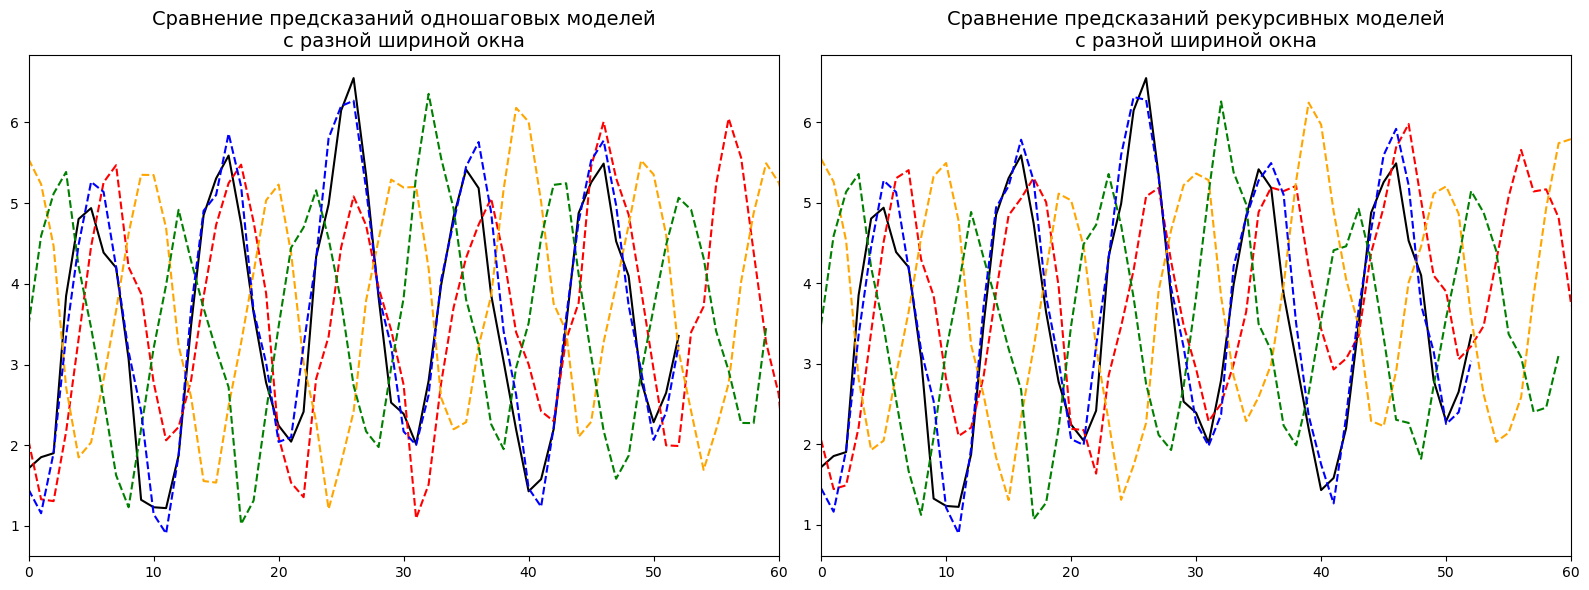

In [72]:
import matplotlib.pyplot as plt

colors = ['red', 'orange', 'green', 'blue', 'purple']

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# =========================
# One-step predictions
# =========================

axes[0].plot(true_future, color='black', label='True')

for pred, color in zip(one_step_preds, colors):
    axes[0].plot(pred, color=color, linestyle='--')

axes[0].set_title(
    'Сравнение предсказаний одношаговых моделей\nс разной шириной окна',
    fontsize=14
)

axes[0].set_xlim(0, 60)


# =========================
# Recursive predictions
# =========================

axes[1].plot(true_future, color='black', label='True')

for pred, color in zip(recursive_preds, colors):
    axes[1].plot(pred, color=color, linestyle='--')

axes[1].set_title(
    'Сравнение предсказаний рекурсивных моделей\nс разной шириной окна',
    fontsize=14
)

axes[1].set_xlim(0, 60)


plt.tight_layout()
plt.show()

In [73]:

# =============================================================
# MAE рекурсивного прогноза для разных горизонтов
# =============================================================

horizons = [1, 5, 10, 20, 30, 60]

horizon_results = []

for w_size, window in windows.items():

    # Берём уже обученную модель
    model = models[w_size]

    # Граница train/test в исходном series
    forecast_origin = len(window['X_train']) + w_size

    # Максимальный горизонт
    max_h = min(
        max(horizons),
        len(series) - forecast_origin
    )

    # Последнее известное окно
    hist = list(
        series[forecast_origin - w_size:forecast_origin]
    )

    # Один рекурсивный прогноз до 60 шагов
    rec_preds = []

    for i in range(max_h):

        x_in = torch.tensor(
            np.array(hist[-w_size:], dtype=np.float32)
        ).unsqueeze(0)

        with torch.no_grad():
            p = model(x_in).item()

        rec_preds.append(p)
        hist.append(p)

    rec_preds = np.array(rec_preds)

    # Реальные будущие значения
    true_future = np.array(
        series[forecast_origin:forecast_origin + max_h]
    )

    # =========================================================
    # MAE для каждого горизонта
    # =========================================================

    for h in horizons:

        if h > max_h:
            continue

        # Рекурсивный MAE
        mae_h = np.mean(
            np.abs(
                rec_preds[:h] - true_future[:h]
            )
        )

        # Наивный прогноз
        naive_preds = np.full(
            h,
            series[forecast_origin - 1]
        )

        naive_mae_h = np.mean(
            np.abs(
                naive_preds - true_future[:h]
            )
        )

        # Сохраняем все три MAE
        horizon_results.append({
            'Размер окна': w_size,
            'Горизонт h': h,
            'Рекурсивный MAE': mae_h,
            'Одношаговый MAE': one_step_mae_results[w_size],
            'Наивный MAE': naive_mae_h
        })

In [74]:
for w_size, window in windows.items():
    forecast_origin = len(window['X_train']) + w_size
    print(
        f'Окно {w_size}: '
        f'X_train={len(window["X_train"])}, '
        f'forecast_origin={forecast_origin}, '
        f'остаток={len(series) - forecast_origin}'
    )

Окно 33: X_train=293, forecast_origin=326, остаток=74
Окно 66: X_train=267, forecast_origin=333, остаток=67
Окно 100: X_train=240, forecast_origin=340, остаток=60
Окно 135: X_train=212, forecast_origin=347, остаток=53


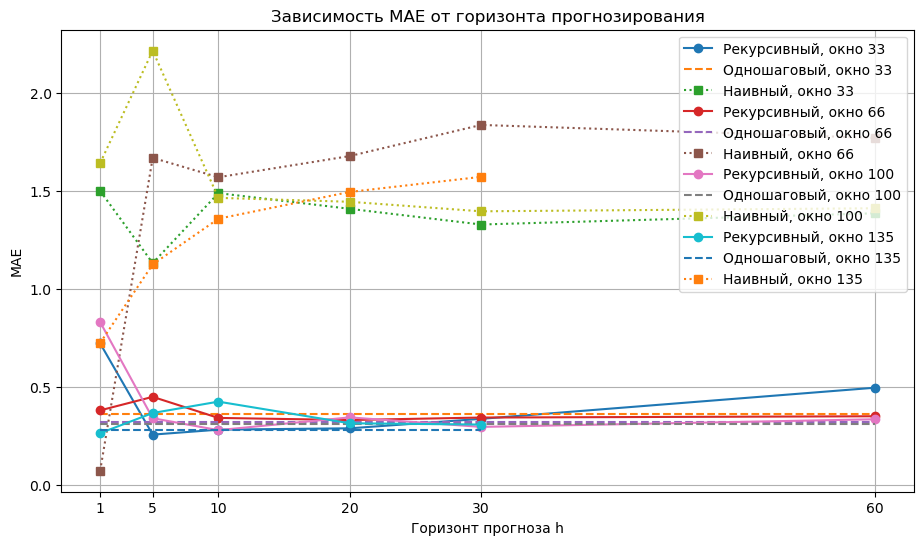

In [75]:
plt.figure(figsize=(11, 6))

for w_size in windows.keys():

    rows = [
        row for row in horizon_results
        if row['Размер окна'] == w_size
    ]

    hs = [
        row['Горизонт h']
        for row in rows
    ]

    recursive_mae = [
        row['Рекурсивный MAE']
        for row in rows
    ]

    one_step_mae = [
        row['Одношаговый MAE']
        for row in rows
    ]

    naive_mae = [
        row['Наивный MAE']
        for row in rows
    ]

    # Рекурсивный прогноз
    plt.plot(
        hs,
        recursive_mae,
        'o-',
        label=f'Рекурсивный, окно {w_size}'
    )

    # Одношаговый MAE — горизонтальная линия
    plt.plot(
        hs,
        one_step_mae,
        '--',
        label=f'Одношаговый, окно {w_size}'
    )

    # Наивный прогноз
    plt.plot(
        hs,
        naive_mae,
        's:',
        label=f'Наивный, окно {w_size}'
    )


plt.xlabel('Горизонт прогноза h')
plt.ylabel('MAE')
plt.title('Зависимость MAE от горизонта прогнозирования')
plt.xticks(horizons)
plt.grid()
plt.legend()
plt.show()

Контрольные вопросы к защите лабораторной работы
1. Почему для временного ряда нельзя использовать случайное (shuffle=True) разбиение на обучающую и тестовую выборки? Что такое утечка данных в этом контексте?

    Соседние по времени точки ряда
    сильно коррелированы (окна, отличающиеся сдвигом на один шаг, почти полностью пересекаются по содержимому), поэтому случайное перемешивание приведёт к утечке данных (data leakage): в обучающей выборке окажутся окна, почти идентичные окнам из
    тестовой выборки, и ошибка на тесте будет неоправданно занижена, не отражая реальной
    способности модели прогнозировать будущее, которого она не видела.
    Правильный способ – разбиение по времени: первые (по хронологии) Ntrain точек
    ряда используются для обучения, последние Ntest точек – исключительно для тестирования, без пересечения:
    [=================== train ===================][====== test ======]
    0 N_train N

2. Опишите метод скользящего окна: как из одного ряда формируется набор пар «входцель» для обучения МСП?

    Пусть задан ряд y0, . . . , yN−1 и выбрана ширина окна W (число «предыдущих» точек,
    подаваемых на вход сети). Обучающая выборка формируется как набор пар «вход – цель»:
    xi = (yi
    , yi+1, . . . , yi+W−1), zi = yi+W , i = 0, . . . , N − W − 1
    То есть каждому окну из W последовательных значений ряда сопоставляется значение, идущее сразу после окна. Сеть обучается решать задачу регрессии zˆ = f(x), где f
    реализуется МСП с W входами и одним линейным выходом:
    zˆ = MLP(yi
    , yi+1, . . . , yi+W−1)
3. Чем отличается одношаговый прогноз от рекурсивного многошагового? Почему рекурсивный прогноз, как правило, менее точен?

    Рекурсивный (рекуррентный по построению, но не по архитектуре) многошаговый прогноз: чтобы предсказать значение на несколько шагов вперёд, не
    имея будущих истинных значений, предсказание сети на шаге t подставляется как
    часть входного окна для прогноза на шаге t + 1, и так далее:
    yˆt+1 = f(yt−W+1, . . . , yt), yˆt+2 = f(yt−W+2, . . . , yt
    , yˆt+1), . . .
    Рекурсивный прогноз неизбежно накапливает ошибку: неточность каждого предсказания «просачивается» во вход для следующего шага, поэтому ошибка рекурсивного прогноза, как правило, заметно превышает ошибку одношагового прогноза и растёт с увеличением горизонта прогнозирования. Это ожидаемый и содержательный результат, который
    следует явно продемонстрировать и прокомментировать в отчёте, а не рассматривать как
    признак ошибки в реализации.

4. Зачем нужен наивный (persistence) базовый прогноз и что означает ситуация, когда
нейросетевая модель его не превосходит?

    Наивный базовый прогноз (persistence baseline) – простейшая модель сравнения:
    yˆt+1 = yt (следующее значение равно последнему известному). Полезно всегда приводить
    MAE/RMSE наивного прогноза рядом с ошибкой нейросетевой модели – если модель не
    превосходит наивный прогноз, это сигнал, что она не выучила ничего содержательного
    сверх простой инерции ряда.

5. Многослойный персептрон не имеет внутреннего состояния (памяти) между вызовами. За счёт чего в этой лабораторной работе он всё же учитывает временную зависимость? Какое архитектурное решение (тема следующих лекций курса) устраняет
необходимость вручную задавать ширину окна?

    MLP учитывает временную зависимость за счёт формирования входных признаков из нескольких предыдущих значений временного ряда — скользящего окна (lag-признаков). Сам MLP памяти между вызовами не имеет. Необходимость вручную задавать размер окна устраняют рекуррентные архитектуры RNN, в частности LSTM и GRU, которые имеют внутреннее состояние и передают информацию о предыдущих временных шагах.

6. Чем отличаются метрики MAE и RMSE? В каком случае они будут сильно расходиться численно?

    • MAE (Mean Absolute Error): MAE =
    1
    n
    Xn
    i=1
    |yi−yˆi
    | – средняя абсолютная ошибка,
    измеряется в тех же единицах, что и сам ряд, устойчива к единичным выбросам.

    • RMSE (Root Mean Squared Error): RMSE =
    vuut
    1
    n
    Xn
    i=1
    (yi − yˆi)
    2 – сильнее штрафует крупные отклонения.